# Módulo 6 Utilización, procesamiento y visualización de grandes volúmenes de datos

*Nombre:* Alejandro Adrián García Martínez

*Matrícula:* A01707109

Se prepara el entorno para trabajar Big Data como se realizó en ejercicios de clase, se crea una SparkSession con 8gb de memoria para spark ya que los archivos son algo grandes.

In [14]:
!pip install -q pyspark

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, avg, count, round

spark = SparkSession.builder \
    .appName("Retrasos_Vuelos") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

print(f"Versión de PySpark: {spark.version}")
print("Sesión de Spark iniciada correctamente.")

Versión de PySpark: 4.0.5
Sesión de Spark iniciada correctamente.


Para este trabajo se eligió el siguiente data set [Flight Status Prediction](https://www.kaggle.com/datasets/robikscube/flight-delay-dataset-20182022/data). Es un dataset grande con una gran cantidad de columnas que permite todo tipo de modelos de predicción. Desde predecir vuelos cancelados hasta predecir que tan retrasado van a llegar.

In [15]:
import os

import kagglehub
path = kagglehub.dataset_download("robikscube/flight-delay-dataset-20182022")

total = 0
for nombre in sorted(os.listdir(path)):
    ruta = os.path.join(path, nombre)
    if os.path.isfile(ruta):
        gb = os.path.getsize(ruta) / (1024 ** 3)
        total += gb
        print(f"{nombre:50s} {gb:.2f} GB")

print(f"\nTamaño total del dataset: {total:.2f} GB")

Using Colab cache for faster access to the 'flight-delay-dataset-20182022' dataset.
Airlines.csv                                       0.00 GB
Combined_Flights_2018.csv                          1.86 GB
Combined_Flights_2018.parquet                      0.21 GB
Combined_Flights_2019.csv                          2.63 GB
Combined_Flights_2019.parquet                      0.29 GB
Combined_Flights_2020.csv                          1.63 GB
Combined_Flights_2020.parquet                      0.17 GB
Combined_Flights_2021.csv                          2.06 GB
Combined_Flights_2021.parquet                      0.23 GB
Combined_Flights_2022.csv                          1.32 GB
Combined_Flights_2022.parquet                      0.14 GB
readme.html                                        0.00 GB
readme.md                                          0.00 GB

Tamaño total del dataset: 10.52 GB


Se trabajará con el archivo de 'Combined_Flights_2022.csv' ya que es el registro de vuelos más reciente disponible así como su tamaño es de 1.32GB.

Se revisa el esquema del DataFrame y se hace una pequeña muestra de las primeras 5 filas para revisar que los datos esten bien.

In [16]:
import glob

archivo = glob.glob(path + "/**/Combined_Flights_2022.csv", recursive=True)[0]
print("Archivo:", archivo)

df = spark.read.csv(archivo, header=True, inferSchema=True)

print("--- ESQUEMA DEL DATAFRAME ---")
df.printSchema()

print("--- MUESTRA DE DATOS ---")
df.show(5)

print("Número de vuelos:", df.count())
print("Número de columnas:", len(df.columns))

Archivo: /kaggle/input/flight-delay-dataset-20182022/Combined_Flights_2022.csv
--- ESQUEMA DEL DATAFRAME ---
root
 |-- FlightDate: date (nullable = true)
 |-- Airline: string (nullable = true)
 |-- Origin: string (nullable = true)
 |-- Dest: string (nullable = true)
 |-- Cancelled: boolean (nullable = true)
 |-- Diverted: boolean (nullable = true)
 |-- CRSDepTime: integer (nullable = true)
 |-- DepTime: double (nullable = true)
 |-- DepDelayMinutes: double (nullable = true)
 |-- DepDelay: double (nullable = true)
 |-- ArrTime: double (nullable = true)
 |-- ArrDelayMinutes: double (nullable = true)
 |-- AirTime: double (nullable = true)
 |-- CRSElapsedTime: double (nullable = true)
 |-- ActualElapsedTime: double (nullable = true)
 |-- Distance: double (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Quarter: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- DayofMonth: integer (nullable = true)
 |-- DayOfWeek: integer (nullable = true)
 |-- Marketing_Airlin

Ya que hay una gran cantidad de columnas que se pueden utilizar, hay que elegir que se busca predecir. En esta ocasión me gustaría hacer uno de los retos que el dataset propone que es predecir qué tiempo de retraso de los vuelos.

Así que las columnas que utilizaré son las siguientes:
- Airline: aerolínea.
- Origin: aeropuerto de origen.
- Month: mes.
- DayOfWeek: día de la semana.
- CRSDepTime: hora de salida programada.
- Distance: distancia en millas.
- CRSElapsedTime: duración programada en minutos.
- DepDelay: minutos de retraso al despegar.
- ArrDelay: minutos de retraso al llegar (la columna a predecir).

También se realiza un 'dropna()' para eliminar los datos faltantes. Los vuelos cancelados o desviados no tienen retraso de llegada por lo que también son eliminados.


In [17]:
columnas = ["Airline", "Origin", "Month", "DayOfWeek", "CRSDepTime",
            "Distance", "CRSElapsedTime", "DepDelay", "ArrDelay"]
vuelos = df.select(columnas)

vuelos = vuelos.dropna()

vuelos.cache()

print("Vuelos después de limpiar:", vuelos.count())
vuelos.show(5)

Vuelos después de limpiar: 3944916
+--------------------+------+-----+---------+----------+--------+--------------+--------+--------+
|             Airline|Origin|Month|DayOfWeek|CRSDepTime|Distance|CRSElapsedTime|DepDelay|ArrDelay|
+--------------------+------+-----+---------+----------+--------+--------------+--------+--------+
|Commutair Aka Cha...|   GJT|    4|        1|      1133|   212.0|          72.0|   -10.0|   -17.0|
|Commutair Aka Cha...|   HRL|    4|        1|       732|   295.0|          77.0|    -4.0|    -1.0|
|Commutair Aka Cha...|   DRO|    4|        1|      1529|   251.0|          70.0|   -15.0|    -3.0|
|Commutair Aka Cha...|   IAH|    4|        1|      1435|   376.0|          90.0|    -5.0|   -18.0|
|Commutair Aka Cha...|   DRO|    4|        1|      1135|   251.0|          70.0|     0.0|     6.0|
+--------------------+------+-----+---------+----------+--------+--------------+--------+--------+
only showing top 5 rows


Se cuenta cuantos vuelos tiene el archivo original y cuantos quedan despues de usar .dropna(). Los vuelos cancelados y desviados no llegan al destino normal por lo que no tienen ArrDelay por lo que también son eliminados. La eliminación de estos datos afecta solo un pequeño porcentaje.

Vuelos originales:  4,078,318
Vuelos eliminados:  133,402 (3.27%)
  - cancelados: 123,192
  - desviados:  10,210


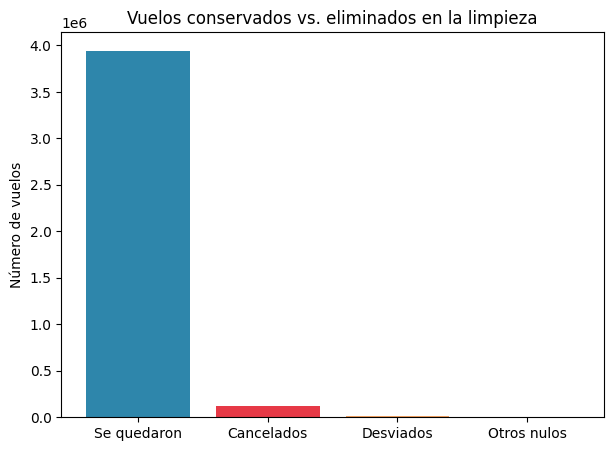

In [18]:
import matplotlib.pyplot as plt

total_original = df.count()
total_limpio = vuelos.count()
eliminados = total_original - total_limpio

cancelados = df.filter(col("Cancelled") == True).count()
desviados = df.filter(col("Diverted") == True).count()

print(f"Vuelos originales:  {total_original:,}")
print(f"Vuelos eliminados:  {eliminados:,} ({eliminados/total_original*100:.2f}%)")
print(f"  - cancelados: {cancelados:,}")
print(f"  - desviados:  {desviados:,}")

etiquetas = ["Se quedaron", "Cancelados", "Desviados", "Otros nulos"]
valores = [total_limpio, cancelados, desviados, max(eliminados - cancelados - desviados, 0)]

plt.figure(figsize=(7, 5))
plt.bar(etiquetas, valores, color=["#2e86ab", "#e63946", "#f4a261", "#999999"])
plt.title("Vuelos conservados vs. eliminados en la limpieza")
plt.ylabel("Número de vuelos")
plt.show()

Se toma el 1% de los datos de los vuelos usando sample(), se pasa a pandas y se realiza un histograma del retraso de llegada, también se utiliza describe() para encontrar el promedio, mediana, mín y máx. La mayoría de los vuelos llega cerca de 0 minutos y la distribución tiene una cola larga hacia la derecha.

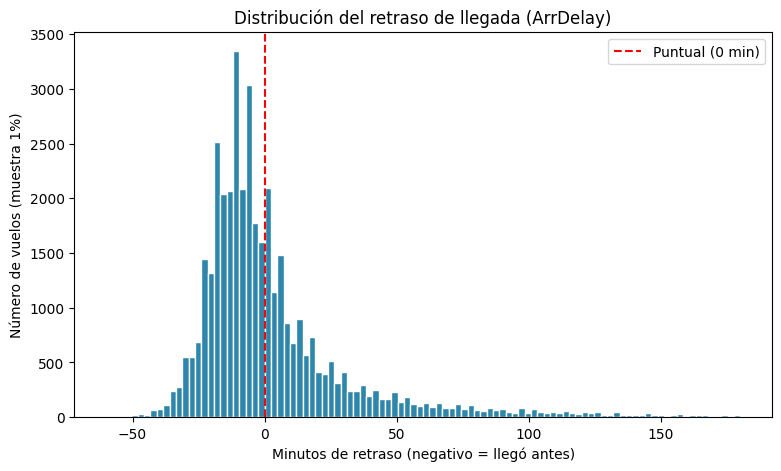

count    39540.00
mean         7.24
std         55.68
min        -70.00
25%        -15.00
50%         -5.00
75%         10.00
max       1643.00
Name: ArrDelay, dtype: float64


In [19]:
muestra = vuelos.select("ArrDelay", "DepDelay").sample(fraction=0.01, seed=42).toPandas()

plt.figure(figsize=(9, 5))
plt.hist(muestra["ArrDelay"], bins=100, range=(-60, 180), color="#2e86ab", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="Puntual (0 min)")
plt.title("Distribución del retraso de llegada (ArrDelay)")
plt.xlabel("Minutos de retraso (negativo = llegó antes)")
plt.ylabel("Número de vuelos (muestra 1%)")
plt.legend()
plt.show()

print(muestra["ArrDelay"].describe().round(2))

Se realiza un gráfico de dispersión para comparar el retraso al despegar con el retraso de llegada. Se puede ver una relación positiva entre ambas variables: cuando aumenta el retraso al despegar, también tiende a aumentar el retraso al llegar. Esto justifica utilizar DepDelay como variable para predecir el retraso de llegada.

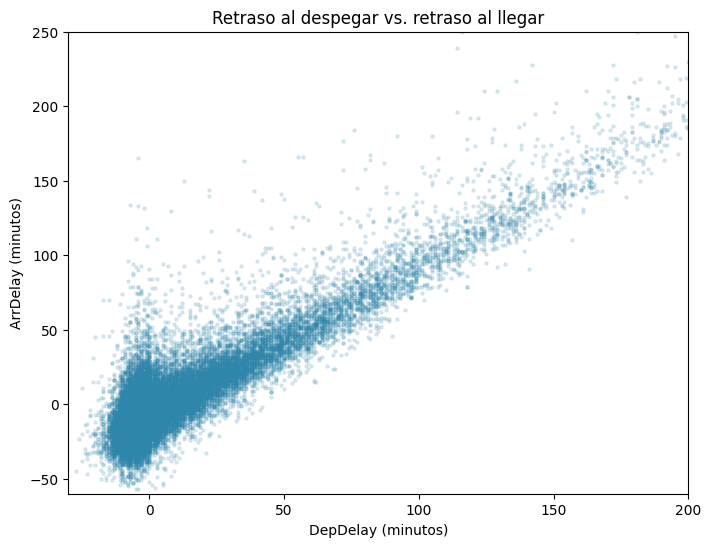

Correlación DepDelay vs ArrDelay: 0.968


In [20]:
plt.figure(figsize=(8, 6))
plt.scatter(muestra["DepDelay"], muestra["ArrDelay"], alpha=0.15, s=5, color="#2e86ab")
plt.xlim(-30, 200)
plt.ylim(-60, 250)
plt.title("Retraso al despegar vs. retraso al llegar")
plt.xlabel("DepDelay (minutos)")
plt.ylabel("ArrDelay (minutos)")
plt.show()

correlacion = vuelos.stat.corr("DepDelay", "ArrDelay")
print(f"Correlación DepDelay vs ArrDelay: {correlacion:.3f}")

Se convierte la hora programada de salida a un valor entero, se agrupan los vuelos por hora y se calcula el retraso promedio de llegada. La gráfica muestra que los retrasos tienden a aumentar durante la tarde y noche, lo que sugiere que la hora de salida programada también influye en los retrasos de llegada.

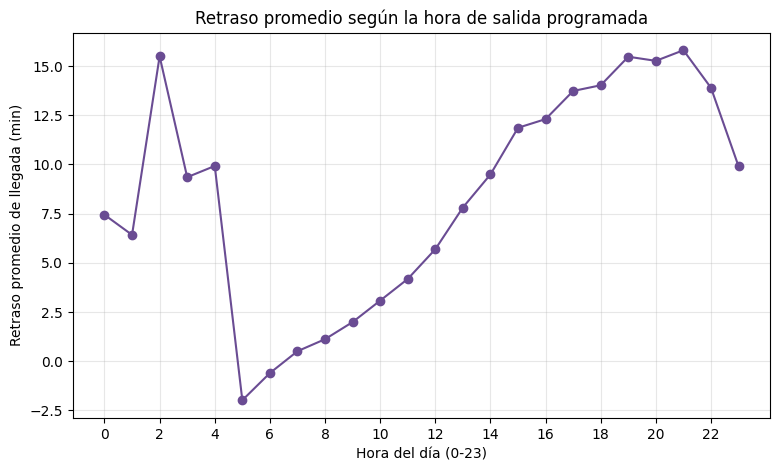

In [21]:
por_hora = (vuelos.withColumn("hora", (col("CRSDepTime") / 100).cast("int"))
            .groupBy("hora")
            .agg(round(avg("ArrDelay"), 2).alias("prom"))
            .orderBy("hora")
            .toPandas())

plt.figure(figsize=(9, 5))
plt.plot(por_hora["hora"], por_hora["prom"], marker="o", color="#6a4c93")
plt.title("Retraso promedio según la hora de salida programada")
plt.xlabel("Hora del día (0-23)")
plt.ylabel("Retraso promedio de llegada (min)")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()

Se realiza una pequeña revisión de los datos para ver el promedio de retraso por aerolínea y el total de vuelos. Como se puede observar, "Allegiant Air" es la aerolínea con mayor tiempo de retraso promedio alcanzando casi 21 min.

También podemos ver que los días con más retraso llegan a ser los viernes, seguidos de los domingos y sábado. Muy probablemente sea porque parte del staff de las aerolíneas descansa y hay más flujo de clientes en el aeropuerto.

In [22]:
print("===== Retraso promedio por aerolínea =====")
vuelos.groupBy("Airline").agg(
    round(avg("ArrDelay"), 2).alias("retraso_promedio"),
    count("*").alias("total_vuelos")
).orderBy(col("retraso_promedio").desc()).show(20, truncate=False)

print("--- Retraso promedio por día de la semana ---")
vuelos.groupBy("DayOfWeek").agg(
    round(avg("ArrDelay"), 2).alias("retraso_promedio")
).orderBy("DayOfWeek").show()

===== Retraso promedio por aerolínea =====
+-----------------------------------------+----------------+------------+
|Airline                                  |retraso_promedio|total_vuelos|
+-----------------------------------------+----------------+------------+
|Allegiant Air                            |20.52           |70452       |
|JetBlue Airways                          |20.01           |148527      |
|Frontier Airlines Inc.                   |17.22           |83894       |
|GoJet Airlines, LLC d/b/a United Express |12.89           |32288       |
|Spirit Air Lines                         |12.23           |124760      |
|American Airlines Inc.                   |9.53            |475871      |
|Comair Inc.                              |9.34            |130135      |
|Mesa Airlines Inc.                       |8.77            |68859       |
|Commutair Aka Champlain Enterprises, Inc.|8.02            |42715       |
|Republic Airlines                        |7.21            |185842   

Ya con una idea general de que sucede en los datos. Se hace una separación 80% train y 20% test. La columna de las aerolíneas se convierte en números para facilitar la identificación (Delta → 0, United → 1, etc.) y que los modelos no tengan problemas al tratar de identificar el texto.

Se usa 'VectorAssembler' para juntar todas las columnas de entrada a una sola llamada "features" ya que así es como lo pide MLlib.

El modelo para predecir será una regresión lineal ya que se espera que bajo las consecuencias correctas (día de la semana sea viernes y sea un vuelo con largo millaje por ejemplo o haya tenido un gran retraso al despegar) el tiempo de retraso sea mayor.

In [13]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression

entrenamiento, prueba = vuelos.randomSplit([0.8, 0.2], seed=42)
print("Vuelos para entrenar:", entrenamiento.count())
print("Vuelos para probar:  ", prueba.count())

indexador = StringIndexer(inputCol="Airline", outputCol="Airline_idx", handleInvalid="keep")
codificador = OneHotEncoder(inputCols=["Airline_idx"], outputCols=["Airline_vec"])

columnas_modelo = ["Month", "DayOfWeek", "CRSDepTime", "Distance",
                   "CRSElapsedTime", "DepDelay", "Airline_vec"]
ensamblador = VectorAssembler(inputCols=columnas_modelo, outputCol="features")

modelo_lr = LinearRegression(featuresCol="features", labelCol="ArrDelay")

pipeline = Pipeline(stages=[indexador, codificador, ensamblador, modelo_lr])

modelo = pipeline.fit(entrenamiento)
print("Modelo entrenado correctamente")

Vuelos para entrenar: 3157307
Vuelos para probar:   787609
Modelo entrenado correctamente


Se utiliza 'modelo.transform(prueba)' para agregar una columna de predicción con lo que el modelo cree que se va a retrasar cada vuelo. Después con ayuda de 'RegressionEvaluator' compara estas predicciones con el retraso real, dando las métricas RMSE, MAE y R cuadrada.

con estos datos podemos saber el error promedio en minutos y el error absoluto. Permitiendo saber que el modelo tiene un error de 9.2 minutos en promedio. Finalmente el valor de la R cuadrada permite saber que tanto estas variables independientes que se eligieron son capaces de explicar la variable dependiente.

Teniendo un valor de 0.94 da a entender que este modelo de regresión lineal puede explicar casi todo con las variables elegidas para predecir. Dando a entender que las columnas elegidas fueron las mejores para la predicción del tiempo de retraso.


In [23]:
from pyspark.ml.evaluation import RegressionEvaluator

predicciones = modelo.transform(prueba)

for metrica in ["rmse", "mae", "r2"]:
    evaluador = RegressionEvaluator(labelCol="ArrDelay", predictionCol="prediction", metricName=metrica)
    print(f"{metrica.upper()}: {evaluador.evaluate(predicciones):.4f}")

RMSE: 13.4193
MAE: 9.2488
R2: 0.9401


Para probar el modelo se hace la predicción de 10 vuelos de pruebas juntos con su retraso real para poder ver que tan cerca está el modelo de predecir de forma precisa.

Así mismo se crean 3 vuelos inventados para ver como el modelo interactúa con datos nuevos.

In [24]:
print("===== Real vs. Predicho (minutos de retraso) =====")
predicciones.select("Airline", "Origin", "DepDelay", "ArrDelay",
                    round("prediction", 1).alias("prediccion")).show(10, truncate=False)

aerolinea = vuelos.select("Airline").first()[0]

nuevos = spark.createDataFrame([
    (aerolinea, 7, 5, 1400, 1200.0, 180.0, 45.0),
    (aerolinea, 7, 5, 1400, 1200.0, 180.0, 0.0),
    (aerolinea, 12, 1, 800, 300.0, 70.0, 10.0),
], ["Airline", "Month", "DayOfWeek", "CRSDepTime", "Distance", "CRSElapsedTime", "DepDelay"])

print("--- Predicciones para vuelos nuevos ---")
modelo.transform(nuevos).select("Month", "Distance", "DepDelay",
                                round("prediction", 1).alias("retraso_llegada_predicho")).show()

===== Real vs. Predicho (minutos de retraso) =====
+---------------------------+------+--------+--------+----------+
|Airline                    |Origin|DepDelay|ArrDelay|prediccion|
+---------------------------+------+--------+--------+----------+
|Air Wisconsin Airlines Corp|ABE   |-11.0   |-27.0   |-20.3     |
|Air Wisconsin Airlines Corp|ABE   |-2.0    |-5.0    |-11.0     |
|Air Wisconsin Airlines Corp|ABE   |32.0    |7.0     |23.2      |
|Air Wisconsin Airlines Corp|ALB   |-9.0    |-13.0   |-18.9     |
|Air Wisconsin Airlines Corp|ATW   |90.0    |76.0    |84.7      |
|Air Wisconsin Airlines Corp|ATW   |-6.0    |-9.0    |-11.9     |
|Air Wisconsin Airlines Corp|ATW   |-10.0   |-30.0   |-15.9     |
|Air Wisconsin Airlines Corp|AVL   |-4.0    |1.0     |-12.7     |
|Air Wisconsin Airlines Corp|AVP   |77.0    |57.0    |68.7      |
|Air Wisconsin Airlines Corp|AVP   |-8.0    |-19.0   |-17.1     |
+---------------------------+------+--------+--------+----------+
only showing top 10 rows


para poder visualizar los datos se exportan a google drive, con estos datos se puede trabajar con tableau para poder presentarlos de forma correcta y ordenada.

Las tablas se pueden ver en el siguiente [Drive](https://drive.google.com/drive/folders/1FLGZWxTdDJl8YT8uIuxMw9-n_oxUNJR1?usp=sharing)

In [25]:
from google.colab import drive
drive.mount("/content/drive")

carpeta = "/content/drive/MyDrive/tablero_vuelos"
os.makedirs(carpeta, exist_ok=True)

por_aerolinea = vuelos.groupBy("Airline").agg(
    round(avg("ArrDelay"), 2).alias("retraso_promedio"),
    count("*").alias("total_vuelos")).toPandas()

por_mes = vuelos.groupBy("Month").agg(
    round(avg("ArrDelay"), 2).alias("retraso_promedio"),
    count("*").alias("total_vuelos")).orderBy("Month").toPandas()

por_dia = vuelos.groupBy("DayOfWeek").agg(
    round(avg("ArrDelay"), 2).alias("retraso_promedio")).orderBy("DayOfWeek").toPandas()

por_origen = vuelos.groupBy("Origin").agg(
    round(avg("ArrDelay"), 2).alias("retraso_promedio"),
    count("*").alias("total_vuelos")).filter(col("total_vuelos") > 5000).toPandas()

muestra_pred = predicciones.sample(fraction=0.005, seed=42).select(
    "Airline", "Origin", "Month", "DayOfWeek", "DepDelay", "ArrDelay",
    round("prediction", 1).alias("prediccion")).toPandas()

por_aerolinea.to_csv(f"{carpeta}/por_aerolinea.csv", index=False)
por_mes.to_csv(f"{carpeta}/por_mes.csv", index=False)
por_dia.to_csv(f"{carpeta}/por_dia.csv", index=False)
por_origen.to_csv(f"{carpeta}/por_origen.csv", index=False)
muestra_pred.to_csv(f"{carpeta}/predicciones.csv", index=False)

print("Archivos guardados en:", carpeta)
print("Filas en la muestra de predicciones:", len(muestra_pred))

Mounted at /content/drive
Archivos guardados en: /content/drive/MyDrive/tablero_vuelos
Filas en la muestra de predicciones: 3941


El dashboard de tablau se encuetra aquí: https://public.tableau.com/app/profile/alejandro.garc.a7574/viz/redicciones_vuelos/Dashboard1?publish=yes

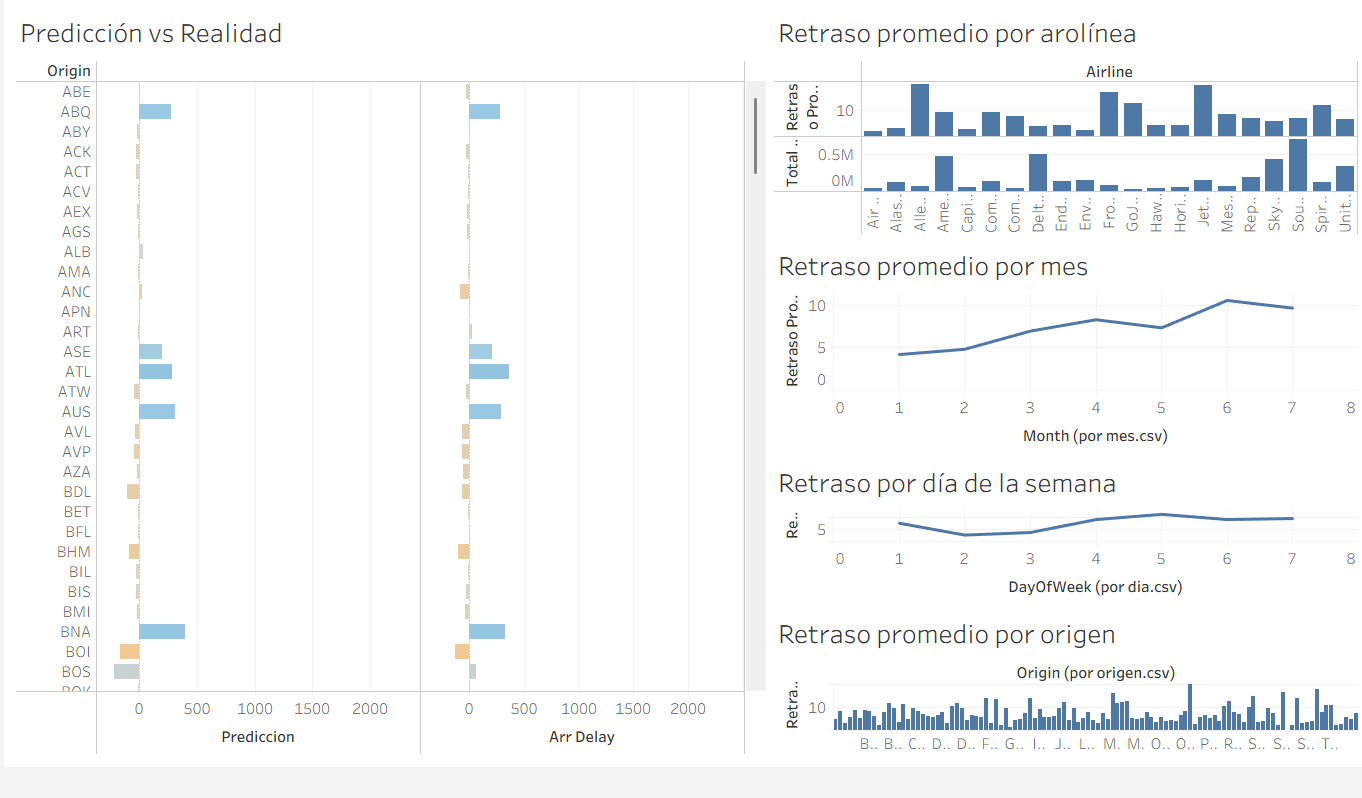